In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.tree import DecisionTreeClassifier,plot_tree
import matplotlib.pyplot as plt

In [3]:
#load dataset
df=pd.read_csv("/home/backup/ml_datasets/adult_income.csv")
print(df)
print(df.head)
print(df.info())
print(df.isnull().sum())

        age     workclass    fnlwgt     education  education-num  \
0      25.0       Private  226802.0          11th            7.0   
1      38.0       Private   89814.0       HS-grad            9.0   
2      28.0     Local-gov  336951.0    Assoc-acdm           12.0   
3      44.0       Private  160323.0  Some-college           10.0   
4      18.0           NaN  103497.0  Some-college           10.0   
...     ...           ...       ...           ...            ...   
48837  27.0       Private  257302.0    Assoc-acdm           12.0   
48838  40.0       Private  154374.0       HS-grad            9.0   
48839  58.0       Private  151910.0       HS-grad            9.0   
48840  22.0       Private  201490.0       HS-grad            9.0   
48841  52.0  Self-emp-inc  287927.0       HS-grad            9.0   

           marital-status         occupation relationship   race     sex  \
0           Never-married  Machine-op-inspct    Own-child  Black    Male   
1      Married-civ-spouse    Fa

In [4]:
x=df.drop('class',axis=1)
print(x)
y=df['class'].map({'<=50K':0,'>50K':1})
print(y)

        age     workclass    fnlwgt     education  education-num  \
0      25.0       Private  226802.0          11th            7.0   
1      38.0       Private   89814.0       HS-grad            9.0   
2      28.0     Local-gov  336951.0    Assoc-acdm           12.0   
3      44.0       Private  160323.0  Some-college           10.0   
4      18.0           NaN  103497.0  Some-college           10.0   
...     ...           ...       ...           ...            ...   
48837  27.0       Private  257302.0    Assoc-acdm           12.0   
48838  40.0       Private  154374.0       HS-grad            9.0   
48839  58.0       Private  151910.0       HS-grad            9.0   
48840  22.0       Private  201490.0       HS-grad            9.0   
48841  52.0  Self-emp-inc  287927.0       HS-grad            9.0   

           marital-status         occupation relationship   race     sex  \
0           Never-married  Machine-op-inspct    Own-child  Black    Male   
1      Married-civ-spouse    Fa

In [5]:
numerical_features=x.select_dtypes(
    include=["int64","float64"]
).columns.tolist()
categorical_features=x.select_dtypes(
    include=["category","object"]
).columns.tolist()
print("Numerical Features\n",numerical_features)
print("Categorical Features\n",categorical_features)

Numerical Features
 ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical Features
 ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [6]:
#Null values
for column in numerical_features:
    x[column]=x[column].fillna(x[column].median())
for column in categorical_features:
    x[column]=x[column].fillna(x[column].mode()[0])
print(x)
print(x.isnull().sum())

        age     workclass    fnlwgt     education  education-num  \
0      25.0       Private  226802.0          11th            7.0   
1      38.0       Private   89814.0       HS-grad            9.0   
2      28.0     Local-gov  336951.0    Assoc-acdm           12.0   
3      44.0       Private  160323.0  Some-college           10.0   
4      18.0       Private  103497.0  Some-college           10.0   
...     ...           ...       ...           ...            ...   
48837  27.0       Private  257302.0    Assoc-acdm           12.0   
48838  40.0       Private  154374.0       HS-grad            9.0   
48839  58.0       Private  151910.0       HS-grad            9.0   
48840  22.0       Private  201490.0       HS-grad            9.0   
48841  52.0  Self-emp-inc  287927.0       HS-grad            9.0   

           marital-status         occupation relationship   race     sex  \
0           Never-married  Machine-op-inspct    Own-child  Black    Male   
1      Married-civ-spouse    Fa

In [7]:
encoder=OneHotEncoder(handle_unknown="ignore",sparse=False)
x_categorical=encoder.fit_transform(x[categorical_features])
encoded_feature_names=(encoder.get_feature_names(categorical_features))
x_categorical=pd.DataFrame(x_categorical,columns=encoded_feature_names,index=x.index)
print("Encoded categorical data shape\n",x_categorical.shape)

Encoded categorical data shape
 (48842, 99)


In [8]:
scaler=StandardScaler()
x_numerical=scaler.fit_transform(x[numerical_features])
x_numerical=pd.DataFrame(x_numerical,columns=numerical_features,index=x.index)
print("Scaled numerical data shape\n",x_numerical.shape)

Scaled numerical data shape
 (48842, 6)


In [9]:
x_processed=pd.concat([x_numerical,x_categorical],axis=1)
print("Final processed data shape\n",x_processed.shape)
print(x_processed)

Final processed data shape
 (48842, 105)
            age    fnlwgt  education-num  capital-gain  capital-loss  \
0     -0.995129  0.351675      -1.197259     -0.144804     -0.217127   
1     -0.046942 -0.945524      -0.419335     -0.144804     -0.217127   
2     -0.776316  1.394723       0.747550     -0.144804     -0.217127   
3      0.390683 -0.277844      -0.030373      0.886874     -0.217127   
4     -1.505691 -0.815954      -0.030373     -0.144804     -0.217127   
...         ...       ...            ...           ...           ...   
48837 -0.849254  0.640492       0.747550     -0.144804     -0.217127   
48838  0.098933 -0.334178      -0.419335     -0.144804     -0.217127   
48839  1.411808 -0.357510      -0.419335     -0.144804     -0.217127   
48840 -1.213941  0.111984      -0.419335     -0.144804     -0.217127   
48841  0.974183  0.930494      -0.419335      1.871315     -0.217127   

       hours-per-week  workclass_Federal-gov  workclass_Local-gov  \
0           -0.034087    

In [10]:
x_train,x_test,y_train,y_test=train_test_split(x_processed,y,test_size=0.2,random_state=42)
print("Splitted")

Splitted


In [11]:
#Logistic Regression
logistic_model=LogisticRegression(max_iter=1000)
logistic_model.fit(x_train,y_train)

LogisticRegression(max_iter=1000)

In [12]:
#Decision tree
tree_model=DecisionTreeClassifier(criterion='entropy',max_depth=3,random_state=42)
tree_model.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

In [13]:
#predictions
log_pred=logistic_model.predict(x_test)
log_comp=pd.DataFrame({"Actual":y_test,"Predicted":log_pred})
print("Logistic Regression\n",log_comp)

Logistic Regression
        Actual  Predicted
7762        0          0
23881       0          0
30507       1          1
28911       0          0
19484       0          1
...       ...        ...
43046       1          1
18798       1          1
29519       1          1
550         0          0
14337       1          1

[9769 rows x 2 columns]


In [14]:
tree_pred=tree_model.predict(x_test)
tree_comp=pd.DataFrame({"Actual":y_test,"Predicted":tree_pred})
print("Decision Tree\n",tree_comp)

Decision Tree
        Actual  Predicted
7762        0          0
23881       0          0
30507       1          1
28911       0          0
19484       0          1
...       ...        ...
43046       1          1
18798       1          1
29519       1          1
550         0          0
14337       1          1

[9769 rows x 2 columns]


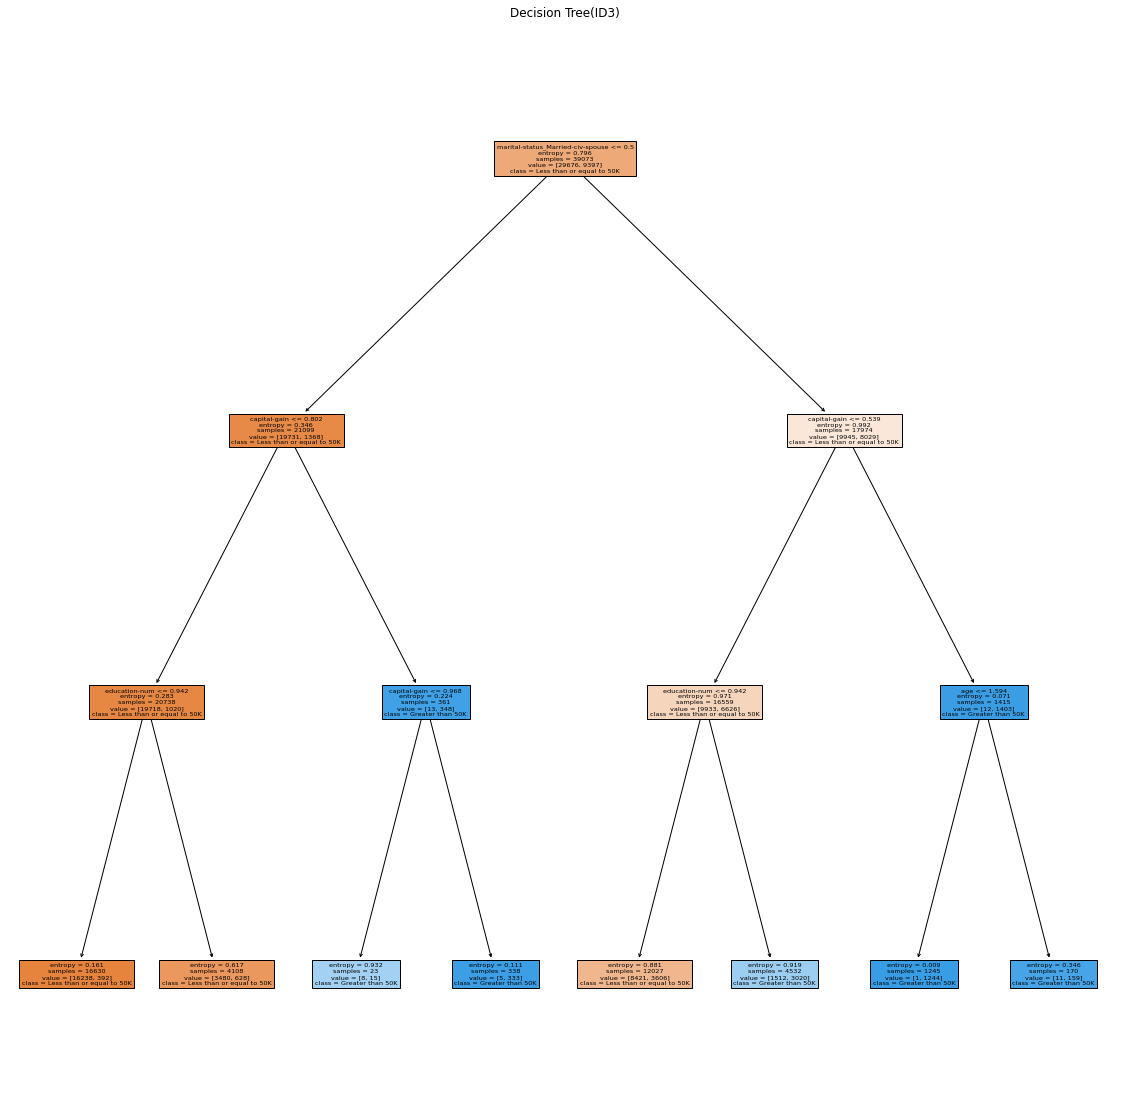

In [15]:
#tree plot
plt.figure(figsize=(20,20))
plot_tree(tree_model,feature_names=x_test.columns,class_names=['Less than or equal to 50K','Greater than 50K'],filled=True)
plt.title("Decision Tree(ID3)")
plt.show()

In [16]:
#metrics comparison
print("Logistic Regression\n\n")
print("Accuracy score ",accuracy_score(y_test,log_pred))
print("Precision ",precision_score(y_test,log_pred))
print("Recall  ",recall_score(y_test,log_pred))
print("F1 score ",f1_score(y_test,log_pred))
print("\n\nConfusion matrix\n\n",confusion_matrix(y_test,log_pred))
print("\n\nClassification Report\n\n",classification_report(y_test,log_pred))

Logistic Regression


Accuracy score  0.8554611526256526
Precision  0.7340085287846482
Recall   0.6013100436681222
F1 score  0.6610657705232836


Confusion matrix

 [[6980  499]
 [ 913 1377]]


Classification Report

               precision    recall  f1-score   support

           0       0.88      0.93      0.91      7479
           1       0.73      0.60      0.66      2290

    accuracy                           0.86      9769
   macro avg       0.81      0.77      0.78      9769
weighted avg       0.85      0.86      0.85      9769



In [17]:
print("Decision tree Classifier\n\n")
print("Accuracy ",accuracy_score(y_test,tree_pred))
print("Precision ",precision_score(y_test,tree_pred))
print("Recall ",recall_score(y_test,tree_pred))
print("F1 Score ",f1_score(y_test,tree_pred))
print("\n\nConfusion matrix\n\n",confusion_matrix(y_test,tree_pred))
print("\n\nClassification report\n\n",classification_report(y_test,tree_pred))

Decision tree Classifier


Accuracy  0.8514689323369843
Precision  0.7650031585596968
Recall  0.52882096069869
F1 Score  0.6253550219468113


Confusion matrix

 [[7107  372]
 [1079 1211]]


Classification report

               precision    recall  f1-score   support

           0       0.87      0.95      0.91      7479
           1       0.77      0.53      0.63      2290

    accuracy                           0.85      9769
   macro avg       0.82      0.74      0.77      9769
weighted avg       0.84      0.85      0.84      9769

